# ShopNow Product Analytics

Product Analytics – Retention, Cohort & Feature Adoption

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Library berhasil di-load.")

Library berhasil di-load.


In [ ]:
users = pd.read_csv('/content/ds_users.csv')
events = pd.read_csv('/content/ds_events.csv')

print("Dataset berhasil dimuat.")

Dataset berhasil dimuat.


In [ ]:
users.head()

,user_id,signup_date,plan,country,retained_day30
0,U0001,2024-01-31,free,Malaysia,1
1,U0002,2024-02-16,free,Singapore,1
2,U0003,2024-01-16,basic,Singapore,1
3,U0004,2024-02-03,basic,Thailand,1
4,U0005,2024-02-15,free,Indonesia,0


In [ ]:
events.head()

,user_id,event_date,event_name,plan,day_since_signup
0,U0001,2024-01-31,search_product,free,0
1,U0001,2024-01-31,search_product,free,0
2,U0001,2024-02-03,app_open,free,3
3,U0001,2024-02-03,search_product,free,3
4,U0001,2024-02-03,view_product,free,3


In [ ]:
print("Ukuran ds_users :", users.shape)
print("Ukuran ds_events:", events.shape)

Ukuran ds_users : (600, 5)
Ukuran ds_events: (38806, 5)


In [ ]:
print("Kolom users:")
print(users.columns.tolist())

print("\nKolom events:")
print(events.columns.tolist())

Kolom users:
['user_id', 'signup_date', 'plan', 'country', 'retained_day30']

Kolom events:
['user_id', 'event_date', 'event_name', 'plan', 'day_since_signup']


In [ ]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   user_id         600 non-null    object
 1   signup_date     600 non-null    object
 2   plan            600 non-null    object
 3   country         600 non-null    object
 4   retained_day30  600 non-null    int64 
dtypes: int64(1), object(4)
memory usage: 23.6+ KB


In [ ]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38806 entries, 0 to 38805
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   user_id           38806 non-null  object
 1   event_date        38806 non-null  object
 2   event_name        38806 non-null  object
 3   plan              38806 non-null  object
 4   day_since_signup  38806 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 1.5+ MB


In [ ]:
users['signup_date'] = pd.to_datetime(users['signup_date'])
events['event_date'] = pd.to_datetime(events['event_date'])

In [ ]:
print(users.dtypes)
print()
print(events.dtypes)

user_id                   object
signup_date       datetime64[ns]
plan                      object
country                   object
retained_day30             int64
dtype: object

user_id                     object
event_date          datetime64[ns]
event_name                  object
plan                        object
day_since_signup             int64
dtype: object


In [ ]:
print("Missing values - users")
print(users.isnull().sum())

print("\nMissing values - events")
print(events.isnull().sum())

Missing values - users
user_id           0
signup_date       0
plan              0
country           0
retained_day30    0
dtype: int64

Missing values - events
user_id             0
event_date          0
event_name          0
plan                0
day_since_signup    0
dtype: int64


In [ ]:
print("Jumlah baris users :", len(users))
print("Jumlah user unik  :", users['user_id'].nunique())

Jumlah baris users : 600
Jumlah user unik  : 600


In [ ]:
users['plan'].value_counts()

,count
plan,
free,337
basic,176
pro,87


In [ ]:
users['retained_day30'].value_counts()

,count
retained_day30,
0,351
1,249


In [ ]:
events['event_name'].value_counts()

,count
event_name,
app_open,8087
search_product,6420
view_product,5798
add_to_cart,4578
view_recommendation,3767
checkout,3315
payment_complete,2746
use_voucher,1816
write_review,1430


In [ ]:
print("Tanggal signup:")
print(users['signup_date'].min())
print(users['signup_date'].max())

print("\nTanggal event:")
print(events['event_date'].min())
print(events['event_date'].max())

Tanggal signup:
2024-01-01 00:00:00
2024-02-29 00:00:00

Tanggal event:
2024-01-01 00:00:00
2024-03-31 00:00:00


Apa itu DAU?

DAU = Daily Active Users

Artinya:

Jumlah user unik yang aktif setiap hari.

Kita gunakan user_id dan event_date.

In [ ]:
dau = (
    events.groupby('event_date')['user_id']
    .nunique()
    .reset_index(name='DAU')
)

dau.head()

,event_date,DAU
0,2024-01-01,3
1,2024-01-02,11
2,2024-01-03,15
3,2024-01-04,23
4,2024-01-05,35


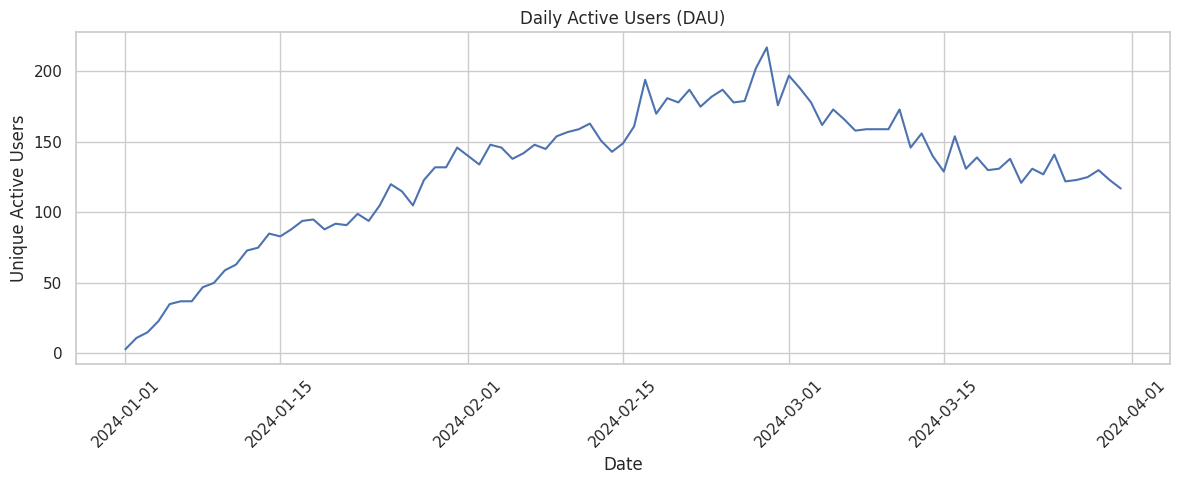

In [ ]:
plt.figure(figsize=(12,5))

sns.lineplot(
    data=dau,
    x='event_date',
    y='DAU'
)

plt.title('Daily Active Users (DAU)')
plt.xlabel('Date')
plt.ylabel('Unique Active Users')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Yang kita cari:
apakah aktivitas stabil?
kapan aktivitas tertinggi?
apakah ada penurunan?

Assignment meminta grafik tren DAU/WAU/MAU.

In [ ]:
###WAU = Weekly Active Users

###Kita hitung user unik setiap minggu.

events['week'] = events['event_date'].dt.to_period('W').astype(str)

wau = (
    events.groupby('week')['user_id']
    .nunique()
    .reset_index(name='WAU')
)

wau.head()

,week,WAU
0,2024-01-01/2024-01-07,57
1,2024-01-08/2024-01-14,146
2,2024-01-15/2024-01-21,187
3,2024-01-22/2024-01-28,220
4,2024-01-29/2024-02-04,270


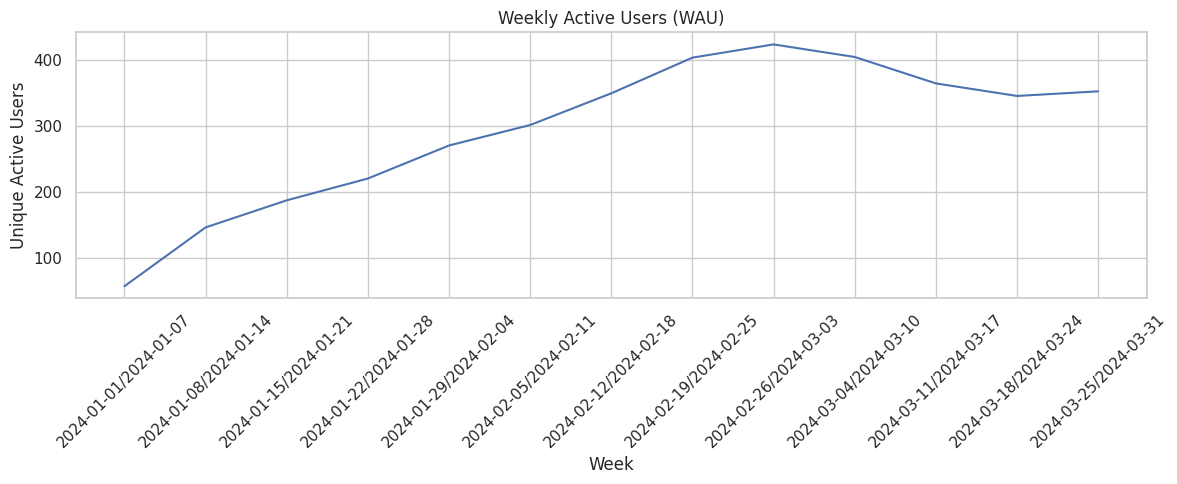

In [ ]:
###VISUALISASI WAU
plt.figure(figsize=(12,5))

sns.lineplot(
    data=wau,
    x='week',
    y='WAU'
)

plt.title('Weekly Active Users (WAU)')
plt.xlabel('Week')
plt.ylabel('Unique Active Users')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

HITUNG MAU

MAU = Monthly Active Users

In [ ]:
events['month'] = events['event_date'].dt.to_period('M').astype(str)

mau = (
    events.groupby('month')['user_id']
    .nunique()
    .reset_index(name='MAU')
)

mau.head()

,month,MAU
0,2024-01,307
1,2024-02,568
2,2024-03,546


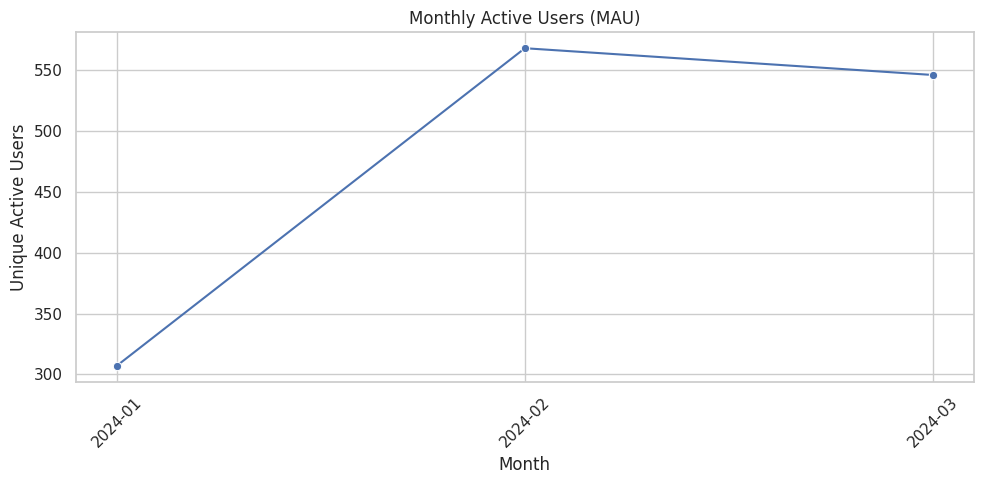

In [ ]:
###VISUALISASI MAU

plt.figure(figsize=(10,5))

sns.lineplot(
    data=mau,
    x='month',
    y='MAU',
    marker='o'
)

plt.title('Monthly Active Users (MAU)')
plt.xlabel('Month')
plt.ylabel('Unique Active Users')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

HITUNG DAY-30 RETENTION

Rumus assignment:

Retention Rate = retained users / total users × 100%

In [ ]:
total_users = users['user_id'].nunique()

retained_users = users['retained_day30'].sum()

retention_rate = retained_users / total_users * 100

print(f"Total Users        : {total_users}")
print(f"Retained Day-30    : {retained_users}")
print(f"Retention Rate     : {retention_rate:.2f}%")

Total Users        : 600
Retained Day-30    : 249
Retention Rate     : 41.50%


Plan mana yang mempunyai retention paling tinggi?

In [ ]:
retention_plan = (
    users.groupby('plan')['retained_day30']
    .agg(['count', 'sum'])
    .reset_index()
)

retention_plan['retention_rate'] = (
    retention_plan['sum'] /
    retention_plan['count'] * 100
)

retention_plan

,plan,count,sum,retention_rate
0,basic,176,88,50.000000
1,free,337,94,27.893175
2,pro,87,67,77.011494


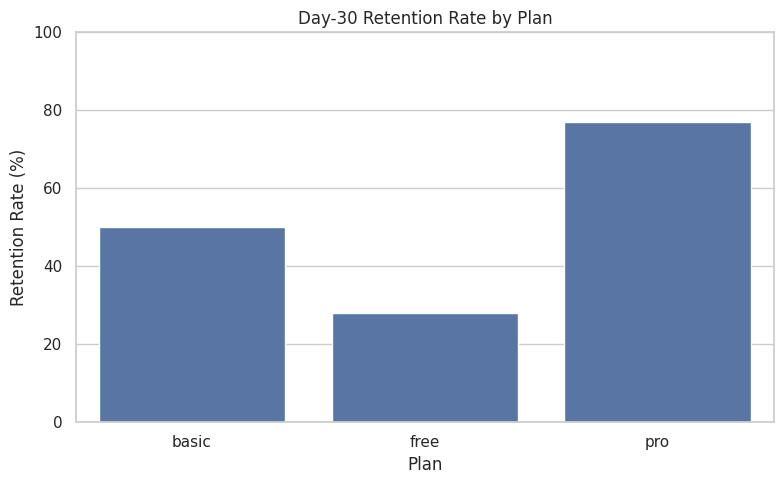

In [ ]:
###VISUALISASI RETENTION PLAN
plt.figure(figsize=(8,5))

sns.barplot(
    data=retention_plan,
    x='plan',
    y='retention_rate'
)

plt.title('Day-30 Retention Rate by Plan')
plt.xlabel('Plan')
plt.ylabel('Retention Rate (%)')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [ ]:
####MEMBUAT COHORT MONTH

###Cohort ditentukan berdasarkan bulan signup.
users['cohort_month'] = (
    users['signup_date']
    .dt.to_period('M')
    .astype(str)
)

users[['user_id', 'signup_date', 'cohort_month']].head()

,user_id,signup_date,cohort_month
0,U0001,2024-01-31,2024-01
1,U0002,2024-02-16,2024-02
2,U0003,2024-01-16,2024-01
3,U0004,2024-02-03,2024-02
4,U0005,2024-02-15,2024-02


User yang signup pada cohort tertentu melakukan aktivitas kapan?

In [ ]:
event_user = events.merge(
    users[['user_id', 'signup_date', 'cohort_month', 'retained_day30']],
    on='user_id',
    how='left',
    suffixes=('_event', '_user')
)

event_user.head()

,user_id,event_date,event_name,plan,day_since_signup,week,month,signup_date,cohort_month,retained_day30
0,U0001,2024-01-31,search_product,free,0,2024-01-29/2024-02-04,2024-01,2024-01-31,2024-01,1
1,U0001,2024-01-31,search_product,free,0,2024-01-29/2024-02-04,2024-01,2024-01-31,2024-01,1
2,U0001,2024-02-03,app_open,free,3,2024-01-29/2024-02-04,2024-02,2024-01-31,2024-01,1
3,U0001,2024-02-03,search_product,free,3,2024-01-29/2024-02-04,2024-02,2024-01-31,2024-01,1
4,U0001,2024-02-03,view_product,free,3,2024-01-29/2024-02-04,2024-02,2024-01-31,2024-01,1


In [ ]:
####HITUNG COHORT INDEX
event_user['event_month'] = (
    event_user['event_date']
    .dt.to_period('M')
)

event_user['cohort_month_period'] = (
    pd.to_datetime(event_user['cohort_month'])
    .dt.to_period('M')
)

event_user['cohort_index'] = (
    (event_user['event_month'].dt.year -
     event_user['cohort_month_period'].dt.year) * 12
    +
    (event_user['event_month'].dt.month -
     event_user['cohort_month_period'].dt.month)
)

In [ ]:
### HITUNG COHORT USER
cohort_users = (
    event_user
    .groupby(['cohort_month', 'cohort_index'])['user_id']
    .nunique()
    .reset_index(name='active_users')
)

cohort_users.head()

,cohort_month,cohort_index,active_users
0,2024-01,0,307
1,2024-01,1,287
2,2024-01,2,275
3,2024-02,0,281
4,2024-02,1,271


In [ ]:
###BUAT COHORT RETENTION

###Kita perlu membandingkan active user dengan jumlah user pada bulan pertama cohort.
cohort_size = (
    cohort_users[cohort_users['cohort_index'] == 0]
    [['cohort_month', 'active_users']]
    .rename(columns={'active_users': 'cohort_size'})
)

cohort_retention = cohort_users.merge(
    cohort_size,
    on='cohort_month',
    how='left'
)

cohort_retention['retention_rate'] = (
    cohort_retention['active_users'] /
    cohort_retention['cohort_size'] * 100
)

cohort_retention.head()

,cohort_month,cohort_index,active_users,cohort_size,retention_rate
0,2024-01,0,307,307,100.000000
1,2024-01,1,287,307,93.485342
2,2024-01,2,275,307,89.576547
3,2024-02,0,281,281,100.000000
4,2024-02,1,271,281,96.441281


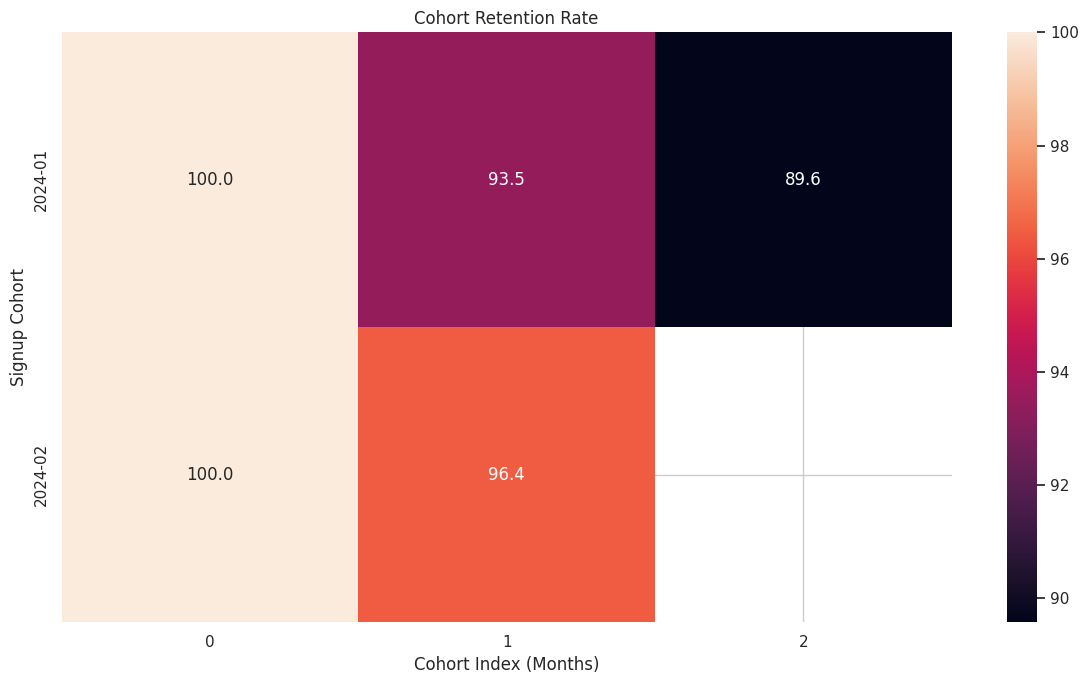

In [ ]:
##COHORT RETENTION HEATMAP
cohort_pivot = cohort_retention.pivot(
    index='cohort_month',
    columns='cohort_index',
    values='retention_rate'
)

plt.figure(figsize=(12,7))

sns.heatmap(
    cohort_pivot,
    annot=True,
    fmt='.1f'
)

plt.title('Cohort Retention Rate')
plt.xlabel('Cohort Index (Months)')
plt.ylabel('Signup Cohort')
plt.tight_layout()
plt.show()

Fitur apa yang paling banyak digunakan?

In [ ]:
####Assignment mendefinisikan Feature Adoption Rate sebagai jumlah user yang pernah menggunakan fitur dibagi total user.
total_users = users['user_id'].nunique()

feature_adoption = (
    events.groupby('event_name')['user_id']
    .nunique()
    .reset_index(name='users_used')
)

feature_adoption['adoption_rate'] = (
    feature_adoption['users_used'] /
    total_users * 100
)

feature_adoption = feature_adoption.sort_values(
    'adoption_rate',
    ascending=False
)

feature_adoption

,event_name,users_used,adoption_rate
1,app_open,553,92.166667
5,search_product,537,89.500000
7,view_product,521,86.833333
0,add_to_cart,491,81.833333
8,view_recommendation,477,79.500000
2,checkout,445,74.166667
4,payment_complete,427,71.166667
6,use_voucher,370,61.666667
9,write_review,324,54.000000
3,invite_friend,243,40.500000


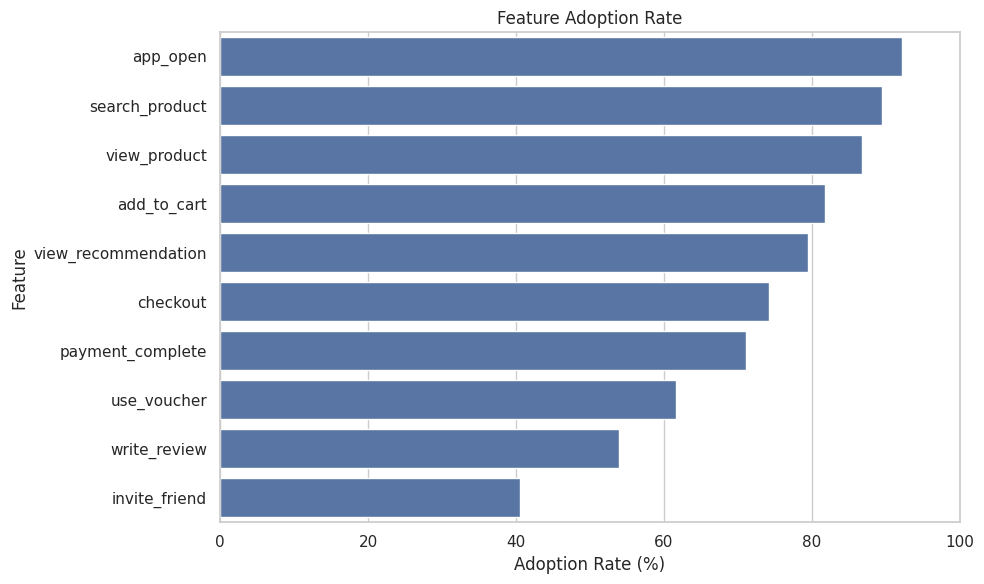

In [ ]:
##VISUALISASI FEATURE ADOPTION
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_adoption,
    x='adoption_rate',
    y='event_name'
)

plt.title('Feature Adoption Rate')
plt.xlabel('Adoption Rate (%)')
plt.ylabel('Feature')
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

FEATURE ADOPTION BERDASARKAN PLAN
Apakah feature adoption berbeda antara Free, Basic, dan Pro?

In [ ]:
feature_plan = (
    events.groupby(['plan', 'event_name'])['user_id']
    .nunique()
    .reset_index(name='users_used')
)

plan_users = (
    users.groupby('plan')['user_id']
    .nunique()
    .reset_index(name='total_users')
)

feature_plan = feature_plan.merge(
    plan_users,
    on='plan',
    how='left'
)

feature_plan['adoption_rate'] = (
    feature_plan['users_used'] /
    feature_plan['total_users'] * 100
)

feature_plan.head()

,plan,event_name,users_used,total_users,adoption_rate
0,basic,add_to_cart,162,176,92.045455
1,basic,app_open,175,176,99.431818
2,basic,checkout,154,176,87.500000
3,basic,invite_friend,96,176,54.545455
4,basic,payment_complete,136,176,77.272727


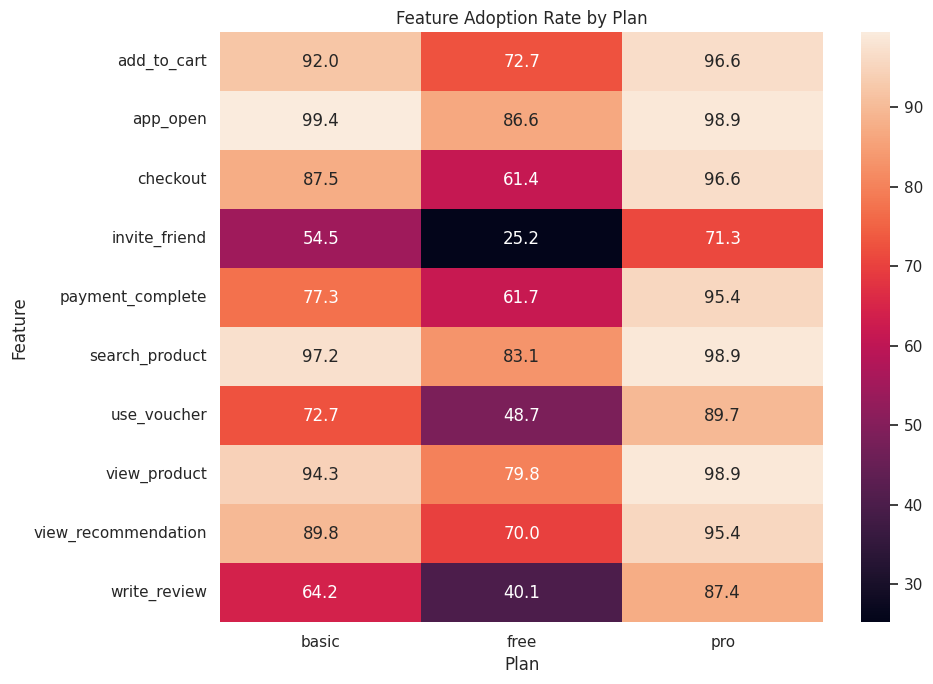

In [ ]:
###HEATMAP FEATURE ADOPTION BY PLAN
feature_plan_pivot = feature_plan.pivot(
    index='event_name',
    columns='plan',
    values='adoption_rate'
)

plt.figure(figsize=(10,7))

sns.heatmap(
    feature_plan_pivot,
    annot=True,
    fmt='.1f'
)

plt.title('Feature Adoption Rate by Plan')
plt.xlabel('Plan')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

RETAINED VS NON-RETAINED

Sekarang kita ingin mengetahui:

Apakah user yang retained lebih banyak menggunakan fitur tertentu?

In [ ]:
events_retention = events.merge(
    users[['user_id', 'retained_day30']],
    on='user_id',
    how='left'
)

In [ ]:
retained_feature = (
    events_retention
    .groupby(['retained_day30', 'event_name'])['user_id']
    .nunique()
    .reset_index(name='users_used')
)

HITUNG ADOPTION RETAINED VS NON-RETAINED

In [ ]:
retained_total = (
    users.groupby('retained_day30')['user_id']
    .nunique()
    .reset_index(name='total_users')
)

retained_feature = retained_feature.merge(
    retained_total,
    on='retained_day30',
    how='left'
)

retained_feature['adoption_rate'] = (
    retained_feature['users_used'] /
    retained_feature['total_users'] * 100
)

retained_feature.head()

,retained_day30,event_name,users_used,total_users,adoption_rate
0,0,add_to_cart,244,351,69.515670
1,0,app_open,304,351,86.609687
2,0,checkout,200,351,56.980057
3,0,invite_friend,64,351,18.233618
4,0,payment_complete,186,351,52.991453


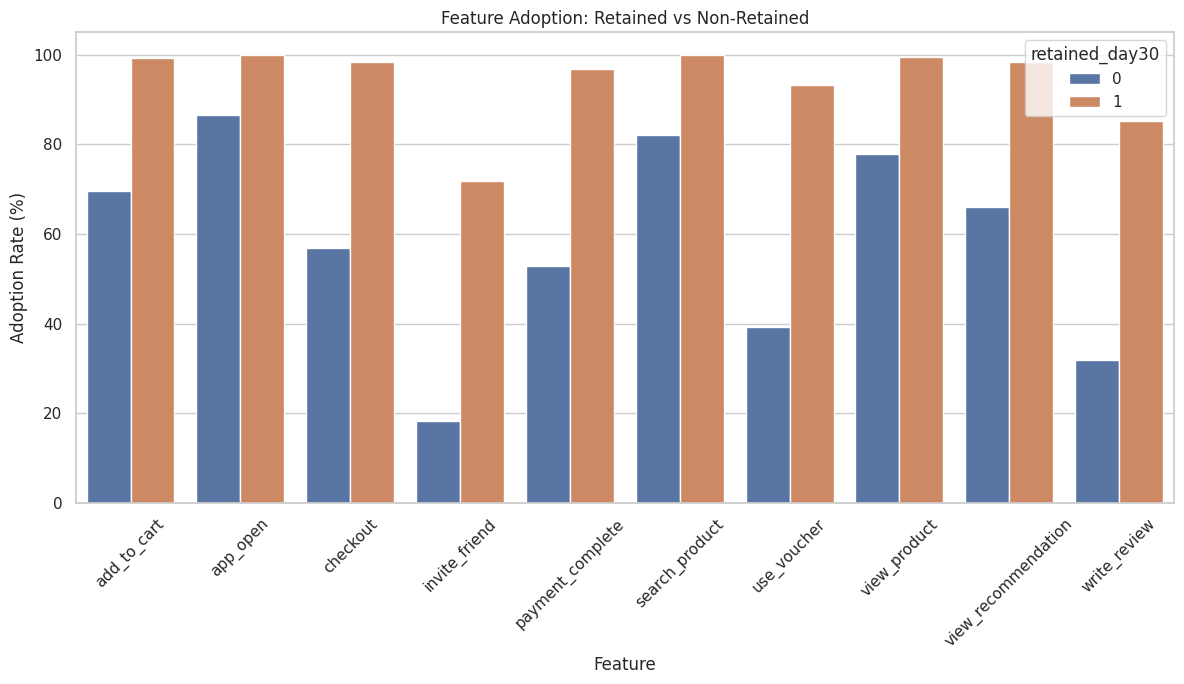

In [ ]:
#####VISUALISASI RETAINED VS NON-RETAINED
plt.figure(figsize=(12,7))

sns.barplot(
    data=retained_feature,
    x='event_name',
    y='adoption_rate',
    hue='retained_day30'
)

plt.title('Feature Adoption: Retained vs Non-Retained')
plt.xlabel('Feature')
plt.ylabel('Adoption Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

ANALISIS 7-DAY FEATURE PRECISION

Assignment meminta mengidentifikasi fitur yang paling banyak digunakan pada 7 hari pertama oleh retained user

In [ ]:
retained_7day = events_retention[
    (events_retention['retained_day30'] == 1) &
    (events_retention['day_since_signup'] <= 7)
]

In [ ]:
precision_7day = (
    retained_7day
    .groupby('event_name')['user_id']
    .nunique()
    .reset_index(name='users_used')
    .sort_values('users_used', ascending=False)
)

precision_7day

,event_name,users_used
1,app_open,215
7,view_product,210
5,search_product,205
0,add_to_cart,184
8,view_recommendation,157
2,checkout,151
4,payment_complete,142
6,use_voucher,97
9,write_review,71
3,invite_friend,70


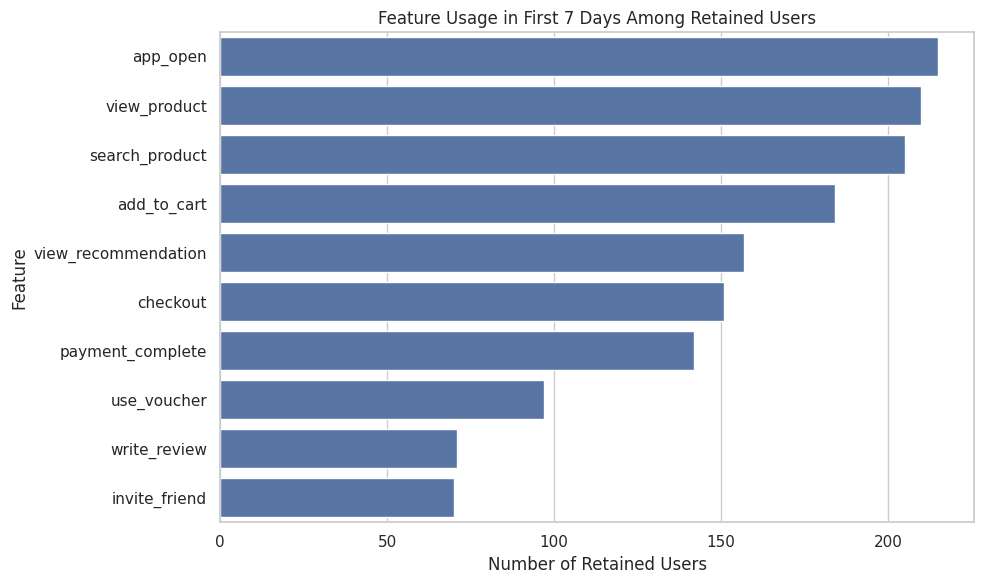

In [ ]:
####VISUALISASI 7-DAY FEATURE
plt.figure(figsize=(10,6))

sns.barplot(
    data=precision_7day,
    x='users_used',
    y='event_name'
)

plt.title('Feature Usage in First 7 Days Among Retained Users')
plt.xlabel('Number of Retained Users')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

BUAT TABEL RINGKASAN UTAMA

Sekarang kita siapkan angka penting untuk laporan.

In [ ]:
summary = pd.DataFrame({
    'Metric': [
        'Total Users',
        'Retained Users',
        'Day-30 Retention Rate',
        'Total Events',
        'Unique Event Types'
    ],
    'Value': [
        users['user_id'].nunique(),
        users['retained_day30'].sum(),
        retention_rate,
        len(events),
        events['event_name'].nunique()
    ]
})

summary

,Metric,Value
0,Total Users,600.0
1,Retained Users,249.0
2,Day-30 Retention Rate,41.5
3,Total Events,38806.0
4,Unique Event Types,10.0


In [ ]:
####SIMPAN HASIL ANALISIS

###Supaya hasil Python kita tidak hilang.
dau.to_csv('DAU.csv', index=False)
wau.to_csv('WAU.csv', index=False)
mau.to_csv('MAU.csv', index=False)

retention_plan.to_csv(
    'Retention_by_Plan.csv',
    index=False
)

cohort_retention.to_csv(
    'Cohort_Retention.csv',
    index=False
)

feature_adoption.to_csv(
    'Feature_Adoption.csv',
    index=False
)

feature_plan.to_csv(
    'Feature_Adoption_by_Plan.csv',
    index=False
)

retained_feature.to_csv(
    'Retained_vs_NonRetained.csv',
    index=False
)

precision_7day.to_csv(
    'Feature_Precision_7Day.csv',
    index=False
)

print("Semua hasil analisis berhasil disimpan.")

Semua hasil analisis berhasil disimpan.


In [ ]:
print("===== EXECUTIVE SUMMARY =====")

print(f"Total Users        : {users['user_id'].nunique():,}")
print(f"Total Events       : {len(events):,}")
print(f"Retained Day-30    : {users['retained_day30'].sum():,}")
print(f"Retention Rate     : {retention_rate:.2f}%")
print(f"Jumlah Plan        : {users['plan'].nunique()}")
print(f"Jumlah Event Type  : {events['event_name'].nunique()}")

===== EXECUTIVE SUMMARY =====
Total Users        : 600
Total Events       : 38,806
Retained Day-30    : 249
Retention Rate     : 41.50%
Jumlah Plan        : 3
Jumlah Event Type  : 10


In [ ]:
####VALIDASI RETENTION
retention_check = pd.DataFrame({
    'Metric': [
        'Total Users',
        'Retained Users',
        'Non-Retained Users',
        'Retention Rate (%)'
    ],
    'Value': [
        users['user_id'].nunique(),
        users['retained_day30'].sum(),
        (users['retained_day30'] == 0).sum(),
        retention_rate
    ]
})

retention_check

,Metric,Value
0,Total Users,600.0
1,Retained Users,249.0
2,Non-Retained Users,351.0
3,Retention Rate (%),41.5


In [ ]:
users['retained_day30']

,retained_day30
0,1
1,1
2,1
3,1
4,0
...,...
595,1
596,1
597,0
598,0


In [ ]:
users['user_id']

,user_id
0,U0001
1,U0002
2,U0003
3,U0004
4,U0005
...,...
595,U0596
596,U0597
597,U0598
598,U0599


In [ ]:
retention_summary = users['retained_day30'].value_counts().sort_index()

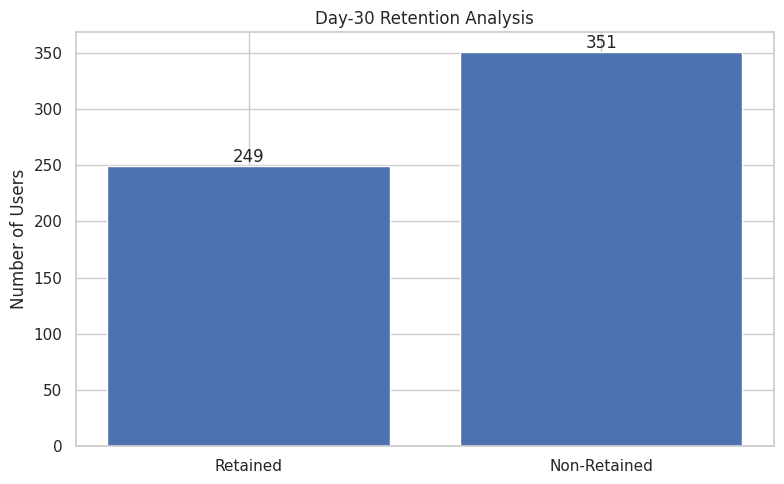

In [ ]:
import matplotlib.pyplot as plt

labels = ['Retained', 'Non-Retained']
values = [retained_users, non_retained_users]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, values)

plt.title('Day-30 Retention Analysis')
plt.ylabel('Number of Users')

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Plan mana yang memiliki retention paling tinggi dan paling rendah?

In [ ]:
retention_plan_sorted = retention_plan.sort_values(
    'retention_rate',
    ascending=False
)

retention_plan_sorted

,plan,count,sum,retention_rate
2,pro,87,67,77.011494
0,basic,176,88,50.000000
1,free,337,94,27.893175


In [ ]:
### Plan tertinggi
top_retention_plan = retention_plan_sorted.iloc[0]

print(
    f"Plan dengan retention tertinggi: "
    f"{top_retention_plan['plan']} "
    f"({top_retention_plan['retention_rate']:.2f}%)"
)

Plan dengan retention tertinggi: pro (77.01%)


In [ ]:
### plan terendah
lowest_retention_plan = retention_plan_sorted.iloc[-1]

print(
    f"Plan dengan retention terendah: "
    f"{lowest_retention_plan['plan']} "
    f"({lowest_retention_plan['retention_rate']:.2f}%)"
)

Plan dengan retention terendah: free (27.89%)


Bagaimana retention user berdasarkan bulan mereka melakukan signup?

In [ ]:
###Tampilkan tabel cohort:
cohort_pivot.round(1)

cohort_index,0,1,2
cohort_month,,,
2024-01,100.0,93.5,89.6
2024-02,100.0,96.4,NaN


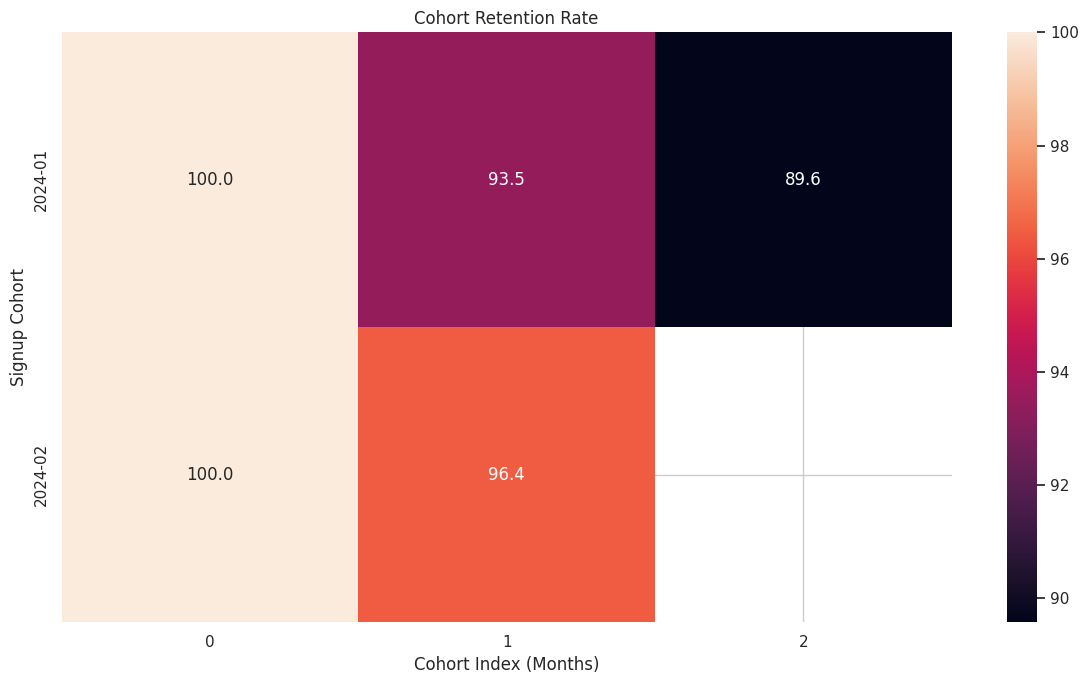

In [ ]:
####Tampilkann Heatmap
plt.figure(figsize=(12,7))

sns.heatmap(
    cohort_pivot,
    annot=True,
    fmt='.1f'
)

plt.title('Cohort Retention Rate')
plt.xlabel('Cohort Index (Months)')
plt.ylabel('Signup Cohort')

plt.tight_layout()
plt.show()

Fitur apa yang paling banyak digunakan user?

In [ ]:
feature_adoption_sorted = feature_adoption.sort_values(
    'adoption_rate',
    ascending=False
)

feature_adoption_sorted

,event_name,users_used,adoption_rate
1,app_open,553,92.166667
5,search_product,537,89.500000
7,view_product,521,86.833333
0,add_to_cart,491,81.833333
8,view_recommendation,477,79.500000
2,checkout,445,74.166667
4,payment_complete,427,71.166667
6,use_voucher,370,61.666667
9,write_review,324,54.000000
3,invite_friend,243,40.500000


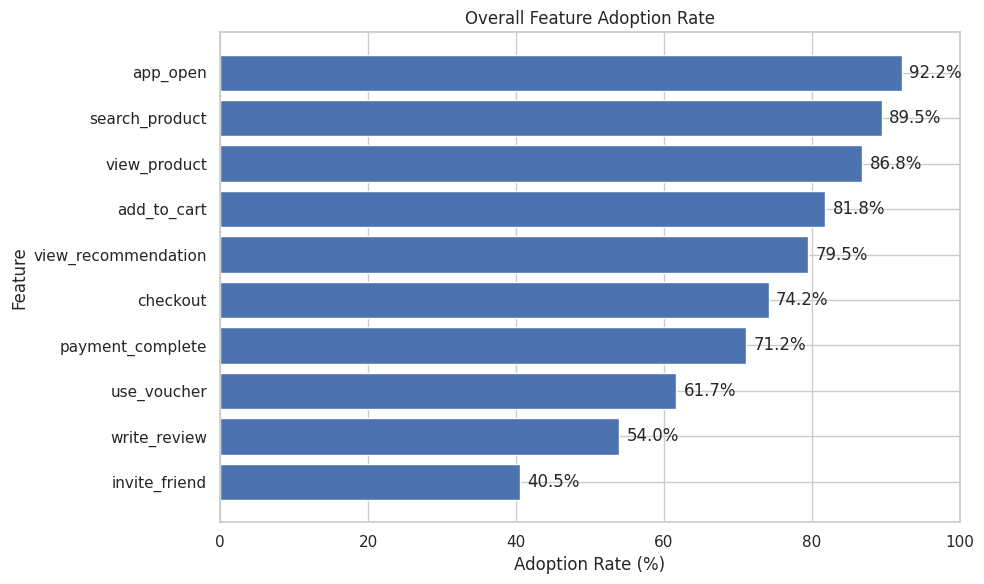

In [ ]:
import matplotlib.pyplot as plt

# Data feature adoption
features = feature_adoption_sorted['event_name']
adoption = feature_adoption_sorted['adoption_rate']

plt.figure(figsize=(10, 6))

bars = plt.barh(features, adoption)

plt.title('Overall Feature Adoption Rate')
plt.xlabel('Adoption Rate (%)')
plt.ylabel('Feature')

plt.xlim(0, 100)
plt.gca().invert_yaxis()

# Menampilkan persentase
for bar, value in zip(bars, adoption):
    plt.text(
        value + 1,
        bar.get_y() + bar.get_height()/2,
        f'{value:.1f}%',
        va='center'
    )

plt.tight_layout()
plt.show()

In [ ]:
feature_adoption_sorted.head(5)

,event_name,users_used,adoption_rate
1,app_open,553,92.166667
5,search_product,537,89.500000
7,view_product,521,86.833333
0,add_to_cart,491,81.833333
8,view_recommendation,477,79.500000


In [ ]:
feature_adoption_sorted.tail(5)

,event_name,users_used,adoption_rate
2,checkout,445,74.166667
4,payment_complete,427,71.166667
6,use_voucher,370,61.666667
9,write_review,324,54.000000
3,invite_friend,243,40.500000


Apakah perilaku penggunaan fitur berbeda berdasarkan plan?

In [ ]:
feature_plan_pivot.round(1)

plan,basic,free,pro
event_name,,,
add_to_cart,92.0,72.7,96.6
app_open,99.4,86.6,98.9
checkout,87.5,61.4,96.6
invite_friend,54.5,25.2,71.3
payment_complete,77.3,61.7,95.4
search_product,97.2,83.1,98.9
use_voucher,72.7,48.7,89.7
view_product,94.3,79.8,98.9
view_recommendation,89.8,70.0,95.4


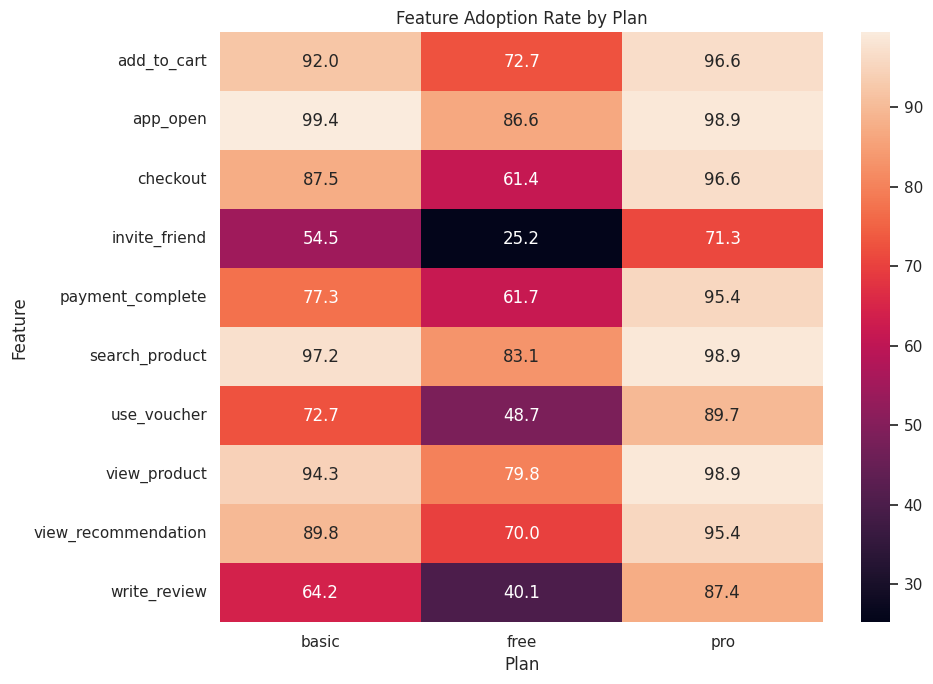

In [ ]:
plt.figure(figsize=(10,7))

sns.heatmap(
    feature_plan_pivot,
    annot=True,
    fmt='.1f'
)

plt.title('Feature Adoption Rate by Plan')
plt.xlabel('Plan')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

Fitur apa yang membedakan user retained dan non-retained?

In [ ]:
retained_pivot = retained_feature.pivot(
    index='event_name',
    columns='retained_day30',
    values='adoption_rate'
)

retained_pivot.columns = [
    'Non-Retained',
    'Retained'
]

retained_pivot['Difference'] = (
    retained_pivot['Retained']
    - retained_pivot['Non-Retained']
)

retained_pivot.sort_values(
    'Difference',
    ascending=False
)

,Non-Retained,Retained,Difference
event_name,,,
use_voucher,39.316239,93.172691,53.856451
invite_friend,18.233618,71.887550,53.653932
write_review,31.908832,85.140562,53.231730
payment_complete,52.991453,96.787149,43.795696
checkout,56.980057,98.393574,41.413517
view_recommendation,66.096866,98.393574,32.296708
add_to_cart,69.515670,99.196787,29.681118
view_product,77.777778,99.598394,21.820616
search_product,82.051282,100.000000,17.948718


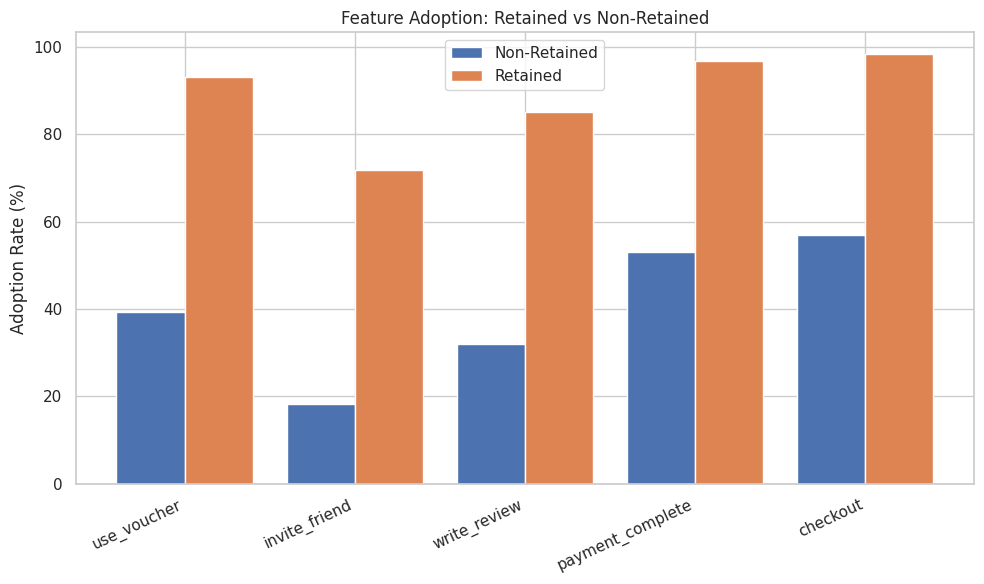

In [ ]:
import matplotlib.pyplot as plt

features = [
    'use_voucher',
    'invite_friend',
    'write_review',
    'payment_complete',
    'checkout'
]

non_retained = [39.32, 18.23, 31.91, 52.99, 56.98]
retained = [93.17, 71.89, 85.14, 96.79, 98.39]

x = range(len(features))

plt.figure(figsize=(10, 6))

plt.bar(
    [i - 0.2 for i in x],
    non_retained,
    width=0.4,
    label='Non-Retained'
)

plt.bar(
    [i + 0.2 for i in x],
    retained,
    width=0.4,
    label='Retained'
)

plt.xticks(x, features, rotation=25, ha='right')
plt.ylabel('Adoption Rate (%)')
plt.title('Feature Adoption: Retained vs Non-Retained')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
precision_7day_sorted = precision_7day.sort_values(
    'users_used',
    ascending=False
)

precision_7day_sorted

,event_name,users_used
1,app_open,215
7,view_product,210
5,search_product,205
0,add_to_cart,184
8,view_recommendation,157
2,checkout,151
4,payment_complete,142
6,use_voucher,97
9,write_review,71
3,invite_friend,70


In [ ]:
precision_7day_sorted.head(5)

,event_name,users_used
1,app_open,215
7,view_product,210
5,search_product,205
0,add_to_cart,184
8,view_recommendation,157


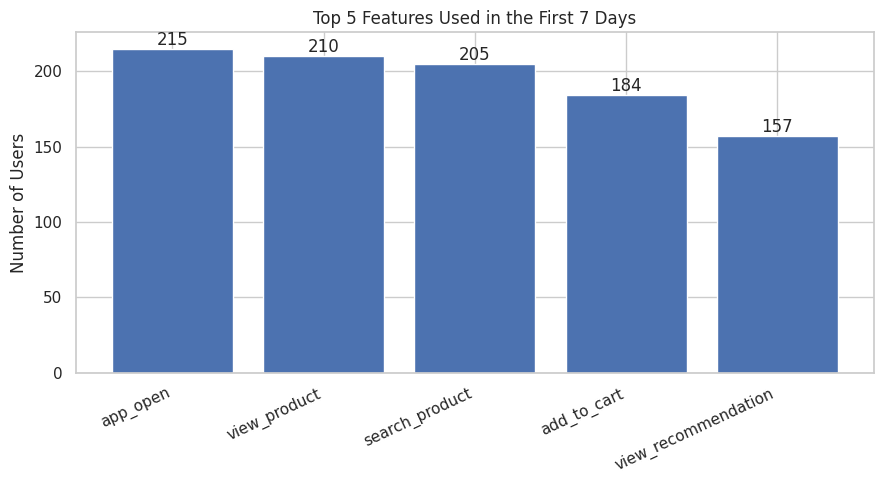

In [ ]:
import matplotlib.pyplot as plt

features = [
    'app_open',
    'view_product',
    'search_product',
    'add_to_cart',
    'view_recommendation'
]

users_used = [215, 210, 205, 184, 157]

plt.figure(figsize=(9, 5))

bars = plt.bar(features, users_used)

plt.title('Top 5 Features Used in the First 7 Days')
plt.ylabel('Number of Users')
plt.xticks(rotation=25, ha='right')

for bar, value in zip(bars, users_used):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        str(value),
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

# Key Findings

1. User Activity
   - DAU, WAU, dan MAU menunjukkan pola aktivitas user.

2. Retention
   - Day-30 retention rate sebesar ...

3. Retention by Plan
   - Plan ... memiliki retention tertinggi.
   - Plan ... memiliki retention terendah.

4. Cohort
   - Cohort ... menunjukkan retention terbaik.
   - Retention mengalami ... setelah cohort index meningkat.

5. Feature Adoption
   - Feature ... memiliki adoption tertinggi.
   - Feature ... memiliki adoption terendah.

6. Retained vs Non-Retained
   - Feature ... memiliki perbedaan adoption terbesar.

7. First 7-Day Usage
   - Feature ... paling banyak digunakan oleh retained users dalam 7 hari pertama.

# Strategic Recommendations

## Recommendation 1 — Strengthen Early User Engagement

Evidence:
app_open merupakan aktivitas yang paling banyak digunakan oleh retained
users dalam 7 hari pertama, dengan 215 users.

Action:
Optimalkan pengalaman pengguna sejak pertama kali membuka aplikasi.
Gunakan onboarding yang sederhana dan arahkan pengguna dari app_open
menuju aktivitas utama seperti view_product, search_product, dan
add_to_cart.

Expected Impact:
Meningkatkan early engagement dan mendorong pengguna untuk melanjutkan
ke aktivitas produk yang lebih dalam sejak awal penggunaan.


## Recommendation 2 — Improve Low-Retention Segment

Evidence:
Free memiliki Day-30 Retention paling rendah, yaitu 27,89%,
dibandingkan Basic sebesar 50,00% dan Pro sebesar 77,01%.

Action:
Fokuskan strategi onboarding dan engagement pada pengguna Free.
Berikan panduan penggunaan fitur utama, edukasi produk, serta
dorongan untuk mencoba fitur yang dapat meningkatkan engagement.

Expected Impact:
Meningkatkan engagement dan Day-30 Retention pada pengguna Free,
yang merupakan segment dengan jumlah users terbesar dan retention
terendah.


## Recommendation 3 — Strengthen Voucher Engagement

Evidence:
use_voucher memiliki perbedaan feature adoption terbesar antara
retained dan non-retained users. Adoption pada retained users sebesar
93,17%, sedangkan pada non-retained users sebesar 39,32%, dengan gap
sebesar 53,86 percentage points.

Action:
Tingkatkan pemanfaatan voucher melalui onboarding, promosi voucher
yang relevan, serta pengingat kepada pengguna agar mencoba dan
menggunakan voucher dalam aktivitas mereka.

Expected Impact:
Meningkatkan engagement terhadap fitur voucher dan membantu
memperkuat aktivitas pengguna selama perjalanan penggunaan produk.